<a href="https://colab.research.google.com/github/ballearun/AIDL_PROJECT/blob/main/AIDL_project_FIRE%26smoke_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

  FIRE & SMOKE DETECTION | 14-Oct-2026 10:39
Image size: 224x224 | Batch: 32 | Epochs per run: 50 (best-epoch weights restored) | Seed: 42
GPU: ['/physical_device:GPU:0']
TensorFlow version: 2.21.0
Output directory: /content/drive/MyDrive/ColabFiles/results
Dataset ZIP: /content/drive/MyDrive/ColabFiles/Untitled Folder/FIRE-SMOKE-DATASET.zip
Planned split: 70% train / 15% validation / 15% test | stratified
Training setup: frozen ImageNet backbone + trainable classifier head | image size 224x224 | head batch 64
Augmentation: 3 random copies per training image (flip, rotation, zoom, shift, brightness, contrast); val/test are NOT augmented
! '/content/drive/MyDrive/ColabFiles/Untitled Folder/FIRE-SMOKE-DATASET.zip' is not a valid zip (251.7 MB). Downloading a fresh copy from GitHub ...
Using dataset zip: /content/FIRE-SMOKE-DATASET.zip (321.0 MB)
Cleaning: remo

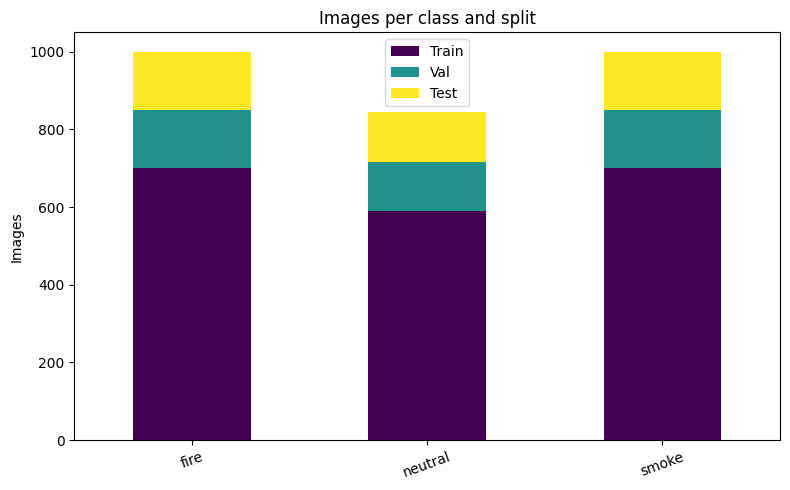

Loaded 2844 images into memory in 4s
Augmentation: +5970 augmented training images generated in 9s -> training set = 1990 original + 5970 augmented = 7960

[figure] 0b_augmentation_examples


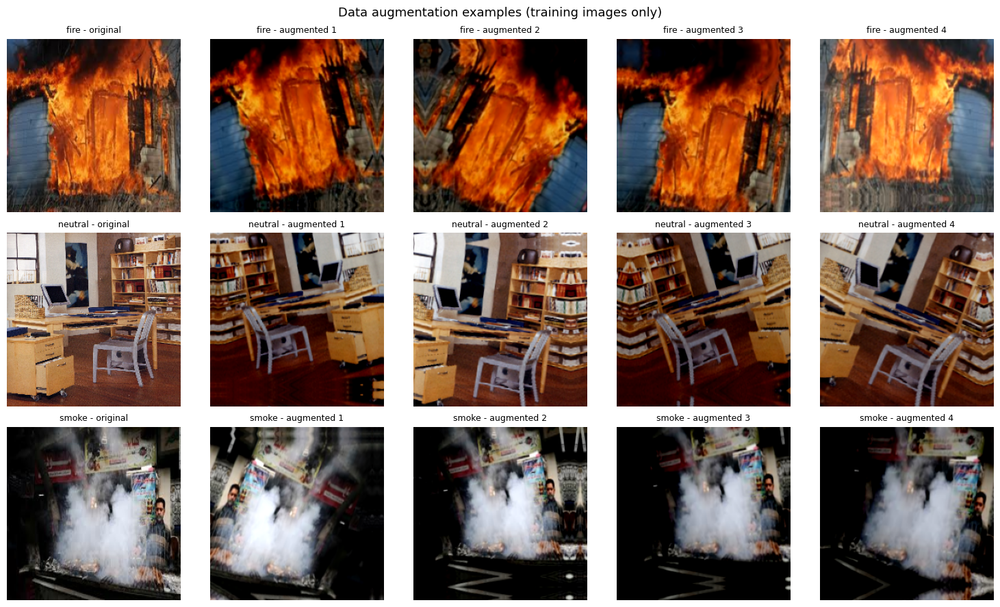


  TRAINING: 28 runs (features cached once per backbone, classifier head trained per optimizer)
Images -> Train: 1990 | Val: 427 | Test: 427 | Total: 2844 | Classes: ['fire', 'neutral', 'smoke']
Epochs -> 50 per run, results shown every 5th epoch (best-val-loss weights restored) | Batch: 32

>>> ResNet50: loading backbone + extracting features (can take 10-60 s) ...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
    ResNet50: 2048-d features for 7960 train images (incl. augmented) extracted in 37s | backbone inference 3.22 ms/img
[1/28] ResNet | ResNet50 + Adam
   EPOCH 05/50 COMPLETED | loss 0.0994 | acc 0.9642 | val_loss 0.1601 | val_acc 0.9461
   EPOCH 10/50 COMPLETED | loss 0.0709 | acc 0.9747 | val_loss 0.1499 | val_acc 0.9532
   EPOCH 15/50 COMPLETED | loss 0.0605 | acc 0.9793 | val_loss 0.1450 | val_acc 0.9602
   EPOCH 20/50 COMPLETED | loss 0.0643 | acc 0.9780 | val_loss 0.1444 | val_acc 0.9602
   EPOCH 25/50 COMPLETED | loss 0.0640 | acc 0.9788 | val_loss 0.1445 | val_acc 

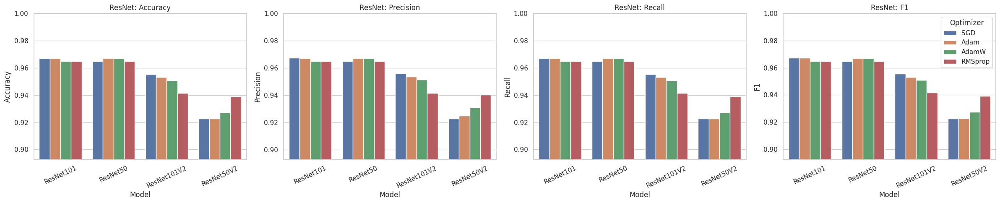


[figure] 2_MobileNet_versions_metrics


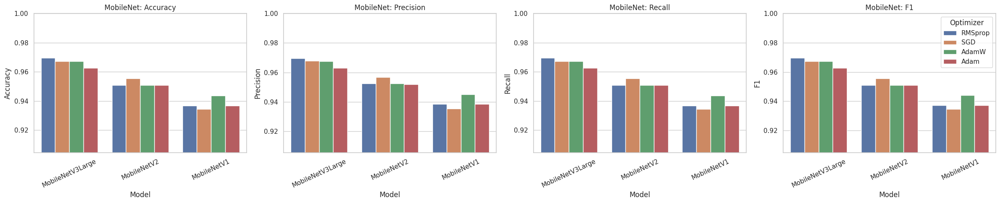


[figure] 3_optimizer_comparison


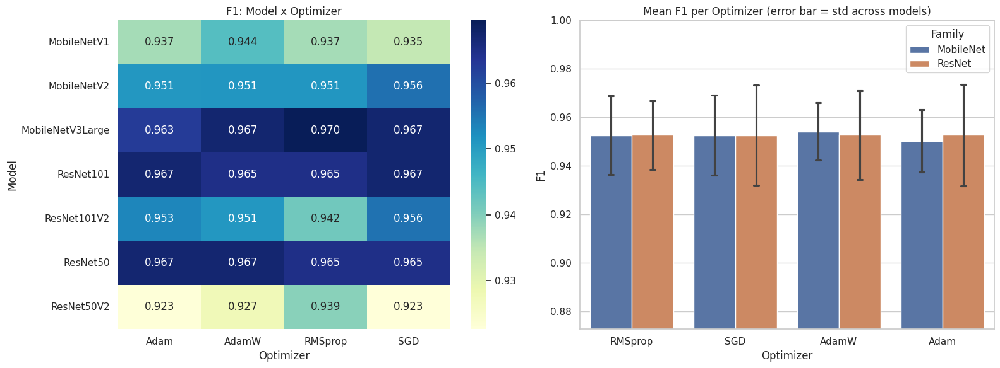


[figure] 4_training_curves


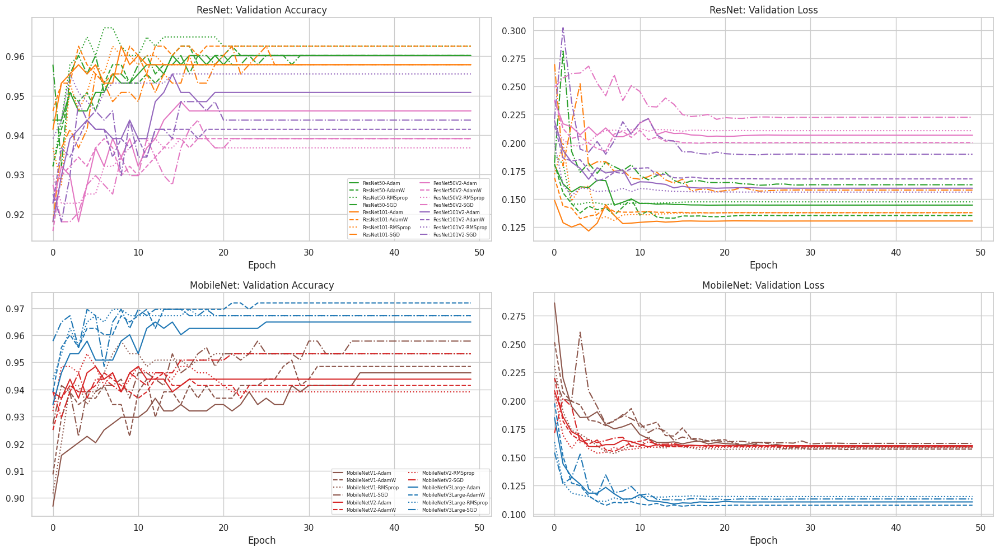


[figure] 5_confusion_roc_best


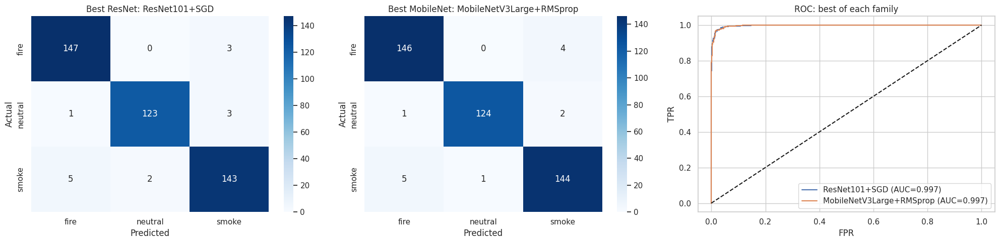


[figure] 6_f1_vs_speed_size


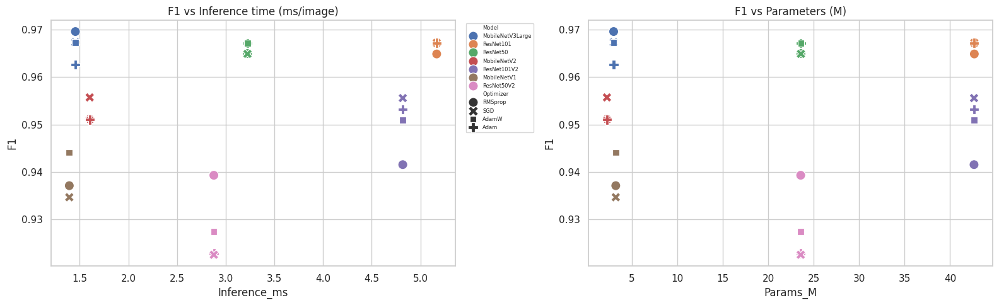


[figure] 7_labeled_vs_detected


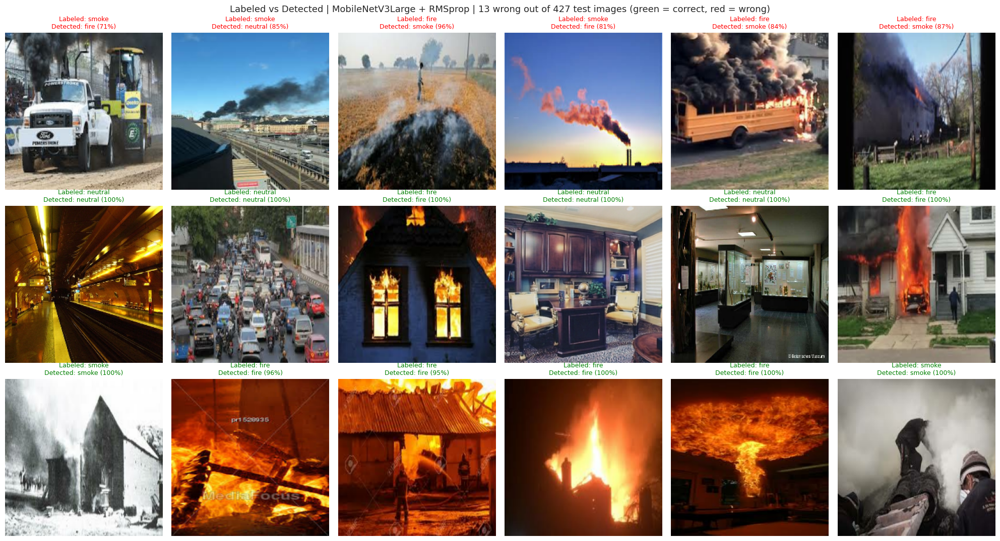


[figure] 8_gradcam_ResNet


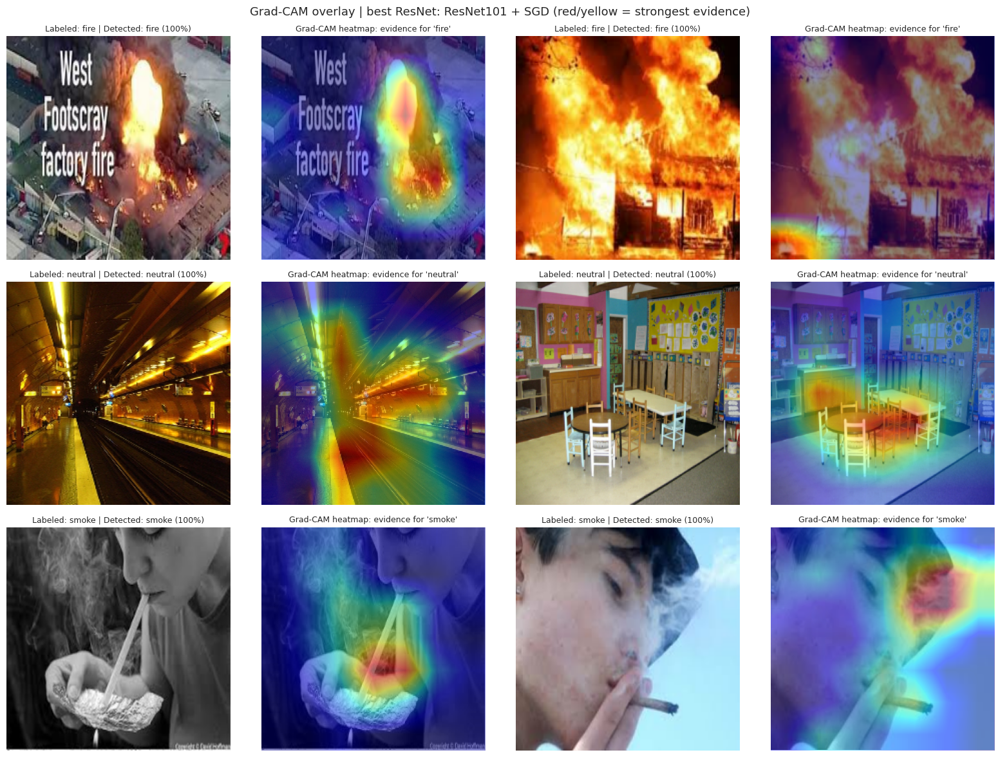


[figure] 8_gradcam_MobileNet


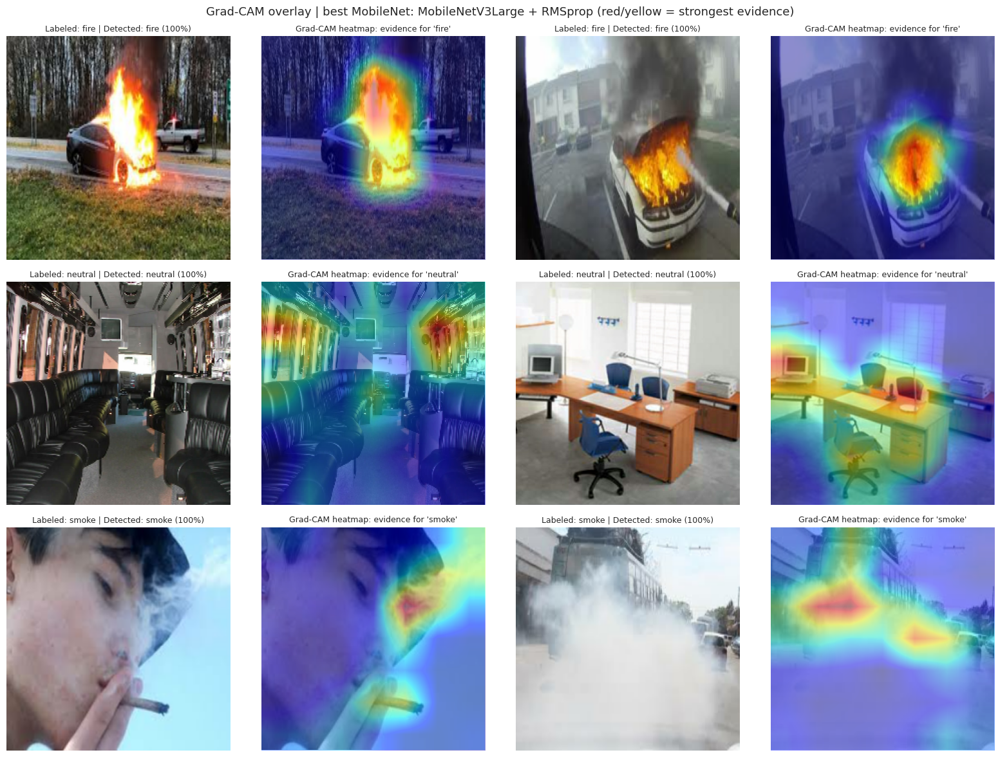

FIRE & SMOKE DETECTION: RESNET vs MOBILENET COMPARISON REPORT
Dataset: 2844 images | Classes: ['fire', 'neutral', 'smoke'] | Split train/val/test: 1990/427/427
Models: ['ResNet50', 'ResNet101', 'ResNet50V2', 'ResNet101V2', 'MobileNetV1', 'MobileNetV2', 'MobileNetV3Large']
Optimizers: ['Adam', 'AdamW', 'RMSprop', 'SGD'] | Epochs: 50 (best-val-loss weights restored) | Frozen ImageNet backbone, features cached | augmentation x3 copies (flip, rotation, zoom, shift, brightness, contrast)

RESULT TABLE (sorted by F1)
               Model Optimizer  Accuracy  Precision  Recall      F1     AUC  Params_M  Inference_ms  Train_min  Epochs_run  Best_epoch     Gap
1   MobileNetV3Large   RMSprop    0.9696     0.9697  0.9696  0.9696  0.9972    2.9992        1.4561     0.3623          50           7 -0.0034
2   MobileNetV3Large       SGD    0.9672     0.9678  0.9672  0.9673  0.9967    2.9992        1.4561     0.3618          50          16 -0.0007
3   MobileNetV3Large     AdamW    0.9672     0.9676  0

In [ ]:
# =====================================================================
# Fire & Smoke Detection: ResNet versions vs MobileNet versions
# x Optimizers (50 epochs) + augmentation + labeled-vs-detected + Grad-CAM heatmaps
# Colab, TF/Keras 3 (fast: frozen-backbone features cached, augmented copies pre-computed)
# =====================================================================
import os, glob, time, zipfile, shutil, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, tensorflow as tf
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from tensorflow.keras import layers, models, applications as apps

drive.mount("/content/drive")                      # mount first: log + results are written straight to Drive

# ---------------- 1. CONFIG ----------------
ZIP_PATH = "/content/drive/MyDrive/ColabFiles/Untitled Folder/FIRE-SMOKE-DATASET.zip"
OUT_DIR  = "/content/drive/MyDrive/ColabFiles/results"
IMG, BATCH, EPOCHS, SEED = 224, 32, 50, 42
AUG_COPIES = 3        # random augmented copies made of every TRAINING image (0 = no augmentation)
HEAD_BATCH = 64       # batch size for the classifier head
QUICK = False        # True = fast smoke test (3 epochs, Adam only, ResNet50 + MobileNetV2) to check everything works
if QUICK: EPOCHS, AUG_COPIES = 3, 1
PATIENCE = EPOCHS      # = run ALL epochs (no early cut-off); best-val-loss weights are restored at the end
os.makedirs(OUT_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

import sys, warnings, datetime
warnings.filterwarnings("ignore")
import io, base64, html
HTML_PATH = f"{OUT_DIR}/full_output.html"            # ONE file: all console text + all plots, in order (like a terminal)
_blocks, _last = [], 0.0
def write_html(force=True):
    global _last
    if not force and time.time() - _last < 3: return
    body = "".join(f"<pre>{html.escape(v)}</pre>" if k == "text" else f'<img src="data:image/png;base64,{v}">' for k, v in _blocks)
    css = ("body{background:#0d1117;color:#e6edf3;font:14px/1.45 Consolas,monospace;margin:20px}pre{white-space:pre-wrap;margin:0}"
           "img{max-width:100%;display:block;margin:14px 0;background:#fff;border-radius:6px}")
    open(HTML_PATH, "w", encoding="utf-8").write(
        f"<html><head><meta charset='utf-8'><title>Fire and Smoke - full output</title><style>{css}</style></head><body>{body}</body></html>")
    _last = time.time()
def log(*args, **kw):                                # print on screen AND add to the single HTML file
    msg = " ".join(str(a) for a in args)
    print(msg, flush=True)
    if _blocks and _blocks[-1][0] == "text": _blocks[-1] = ("text", _blocks[-1][1] + msg + "\n")
    else: _blocks.append(("text", msg + "\n"))
    write_html(force=False)
def show_fig():                                      # show plot on screen AND embed it in the HTML at this point
    buf = io.BytesIO(); plt.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    _blocks.append(("img", base64.b64encode(buf.getvalue()).decode())); plt.show(); write_html()
def banner(t): log("\n" + "=" * 72 + f"\n  {t}\n" + "=" * 72)
banner(f"FIRE & SMOKE DETECTION | {datetime.datetime.now():%d-%b-%Y %H:%M}")
log(f"Image size: {IMG}x{IMG} | Batch: {BATCH} | Epochs per run: {EPOCHS} (best-epoch weights restored) | Seed: {SEED}")
log(f"GPU: {[g.name for g in tf.config.list_physical_devices('GPU')] or 'none (CPU - will be slow)'}")
log(f"TensorFlow version: {tf.__version__}")
log(f"Output directory: {OUT_DIR}")
log(f"Dataset ZIP: {ZIP_PATH}")
log("Planned split: 70% train / 15% validation / 15% test | stratified")
log(f"Training setup: frozen ImageNet backbone + trainable classifier head | image size {IMG}x{IMG} | head batch {HEAD_BATCH}")
log(f"Augmentation: {AUG_COPIES} random copies per training image (flip, rotation, zoom, shift, brightness, contrast); val/test are NOT augmented")

# ---------------- 2. LOAD DATA ----------------
DATASET_URL = "https://github.com/DeepQuestAI/Fire-Smoke-Dataset/releases/download/v1/FIRE-SMOKE-DATASET.zip"
if not zipfile.is_zipfile(ZIP_PATH):                          # corrupt / half-uploaded / wrong file -> fetch a fresh copy
    size = f"{os.path.getsize(ZIP_PATH)/1e6:.1f} MB" if os.path.exists(ZIP_PATH) else "file not found"
    log(f"! '{ZIP_PATH}' is not a valid zip ({size}). Downloading a fresh copy from GitHub ...")
    import urllib.request
    ZIP_PATH = "/content/FIRE-SMOKE-DATASET.zip"
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
assert zipfile.is_zipfile(ZIP_PATH), "Downloaded file is still not a valid zip - check internet / the dataset link."
log(f"Using dataset zip: {ZIP_PATH} ({os.path.getsize(ZIP_PATH)/1e6:.1f} MB)")
shutil.rmtree("/content/data", ignore_errors=True)            # always extract fresh (no stale old dataset)
with zipfile.ZipFile(ZIP_PATH) as z: z.extractall("/content/data")

exts = ("jpg", "jpeg", "png", "bmp")
files = sorted({f for e in exts for f in glob.glob(f"/content/data/**/*.{e}", recursive=True)
                + glob.glob(f"/content/data/**/*.{e.upper()}", recursive=True)})
# drop Mac metadata (__MACOSX, ._files) and any image TensorFlow cannot decode
n0 = len(files)
files = [f for f in files if "__MACOSX" not in f and not os.path.basename(f).startswith("._")]
n_meta = n0 - len(files)
def readable(f):
    try: tf.io.decode_image(tf.io.read_file(f), channels=3, expand_animations=False); return True
    except Exception: return False
bad = [f for f in files if not readable(f)]
bad_set = set(bad); files = [f for f in files if f not in bad_set]
log(f"Cleaning: removed {n_meta} Mac metadata files + {len(bad)} unreadable images -> {len(files)} valid images kept")
for f in bad[:5]: log("   unreadable:", f)
labels_txt = [os.path.basename(os.path.dirname(f)).lower() for f in files]   # class = parent folder (Train/Fire & Test/fire merge)
classes = sorted(set(labels_txt)); NC = len(classes)
y_all = np.array([classes.index(l) for l in labels_txt], dtype=np.int32)
log(f"Images: {len(files)} | Classes ({NC}): {classes}")
log({c: labels_txt.count(c) for c in classes})                       # images per class
assert NC >= 2, (f"Only {NC} class folder found: {classes}. Classification needs >= 2 class folders "
                 f"(e.g. fire/, smoke/, neutral/). Check the zip structure with: !find /content/data -maxdepth 3 -type d")
assert len(files) >= 300, f"Only {len(files)} images - too few for a meaningful train/val/test split."

X_tr, X_tmp, y_tr, y_tmp = train_test_split(files, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_va, X_te, y_va, y_te   = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
banner("DATASET SUMMARY")
cname = lambda y: pd.Series(y).map(lambda i: classes[i])
summ = pd.DataFrame({"Train": cname(y_tr).value_counts(), "Val": cname(y_va).value_counts(),
                     "Test": cname(y_te).value_counts()}).fillna(0).astype(int)
summ["Total"] = summ.sum(axis=1); summ.loc["TOTAL"] = summ.sum()
log(summ.to_string())
log(f"\nSplit: Train {len(X_tr)} ({len(X_tr)/len(files):.0%}) | Val {len(X_va)} ({len(X_va)/len(files):.0%}) | "
      f"Test {len(X_te)} ({len(X_te)/len(files):.0%}) | stratified")
summ.drop(index="TOTAL")[["Train", "Val", "Test"]].plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Images per class and split"); plt.ylabel("Images"); plt.xticks(rotation=20)
plt.tight_layout(); show_fig()

def load_images(paths):                      # decode + resize ONCE -> uint8 array reused by every model
    def load(p):
        img = tf.image.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        return tf.cast(tf.image.resize(img, (IMG, IMG)), tf.uint8)
    ds = tf.data.Dataset.from_tensor_slices(np.array(paths, dtype=str)).map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(128)
    return np.concatenate(list(ds.as_numpy_iterator()))
t0 = time.time(); I_tr, I_va, I_te = load_images(X_tr), load_images(X_va), load_images(X_te)
log(f"Loaded {len(files)} images into memory in {time.time()-t0:.0f}s")

# ---- data augmentation (generated once, reused by every backbone) ----
aug_layers = tf.keras.Sequential([
    layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1), layers.RandomBrightness(0.2, value_range=(0, 255)), layers.RandomContrast(0.2)])
def augment(imgs, copies):
    out = []
    for _ in range(copies):
        for i in range(0, len(imgs), 64):
            x = aug_layers(tf.cast(imgs[i:i+64], tf.float32), training=True)
            out.append(tf.cast(tf.clip_by_value(x, 0, 255), tf.uint8).numpy())
    return np.concatenate(out)
if AUG_COPIES:
    t0 = time.time(); I_aug = augment(I_tr, AUG_COPIES); y_aug = np.tile(y_tr, AUG_COPIES)
    log(f"Augmentation: +{len(I_aug)} augmented training images generated in {time.time()-t0:.0f}s "
        f"-> training set = {len(I_tr)} original + {len(I_aug)} augmented = {len(I_tr)+len(I_aug)}")
    fig, ax = plt.subplots(NC, 5, figsize=(15, 3 * NC))                 # one example per class: original + 4 augmented
    for r, c in enumerate(range(NC)):
        i = np.where(y_tr == c)[0][0]
        vs = aug_layers(tf.cast(np.repeat(I_tr[i:i+1], 4, axis=0), tf.float32), training=True).numpy().clip(0, 255).astype("uint8")
        for k, im in enumerate([I_tr[i], *vs]):
            ax[r, k].imshow(im); ax[r, k].axis("off"); ax[r, k].set_title(f"{classes[c]} - " + ("original" if k == 0 else f"augmented {k}"), fontsize=9)
    fig.suptitle("Data augmentation examples (training images only)", fontsize=13)
    log("\n[figure] 0b_augmentation_examples"); plt.tight_layout(); show_fig()

# ---------------- 3. MODELS (2 families) & OPTIMIZERS ----------------
FAMILIES = {
    "ResNet": {
        "ResNet50":    (apps.ResNet50,    apps.resnet.preprocess_input),
        "ResNet101":   (apps.ResNet101,   apps.resnet.preprocess_input),
        "ResNet50V2":  (apps.ResNet50V2,  apps.resnet_v2.preprocess_input),
        "ResNet101V2": (apps.ResNet101V2, apps.resnet_v2.preprocess_input),
    },
    "MobileNet": {
        "MobileNetV1":      (apps.MobileNet,        apps.mobilenet.preprocess_input),
        "MobileNetV2":      (apps.MobileNetV2,      apps.mobilenet_v2.preprocess_input),
        "MobileNetV3Large": (apps.MobileNetV3Large, apps.mobilenet_v3.preprocess_input),  # preprocessing built in
    },
}
OPTIMIZERS = {
    "Adam":    lambda: tf.keras.optimizers.Adam(1e-3),
    "AdamW":   lambda: tf.keras.optimizers.AdamW(1e-3, weight_decay=1e-4),
    "RMSprop": lambda: tf.keras.optimizers.RMSprop(1e-3),
    "SGD":     lambda: tf.keras.optimizers.SGD(1e-2, momentum=0.9),
}  # 7 models x 4 optimizers = 28 runs; comment out an optimizer to save time

if QUICK:
    FAMILIES = {"ResNet": {"ResNet50": FAMILIES["ResNet"]["ResNet50"]},
                "MobileNet": {"MobileNetV2": FAMILIES["MobileNet"]["MobileNetV2"]}}
    OPTIMIZERS = {"Adam": OPTIMIZERS["Adam"]}

def backbone(fn):                            # frozen ImageNet backbone -> one feature vector per image
    base = fn(include_top=False, weights="imagenet", pooling="avg", input_shape=(IMG, IMG, 3))
    base.trainable = False
    return base
def head_model(dim):                         # the only part that is trained
    return models.Sequential([layers.Input((dim,)), layers.Dropout(0.3), layers.Dense(NC, activation="softmax")])
def extract(base, pre, imgs, bs=64):
    return np.concatenate([base.predict_on_batch(pre(imgs[i:i+bs].astype("float32"))) for i in range(0, len(imgs), bs)])
def rebuild(mname, oname):                   # backbone + trained head for a finished run
    fn, pre = next(g[mname] for g in FAMILIES.values() if mname in g)
    base = backbone(fn); head = head_model(base.output_shape[-1]); head.set_weights(weights[(mname, oname)])
    return base, head, pre

# ---------------- 4. TRAIN + EVALUATE ----------------
class EpochLog(tf.keras.callbacks.Callback):             # prints only every 5th epoch (5, 10, ..., 50)
    def on_epoch_begin(s, e, logs=None): s.t = time.time()
    def on_epoch_end(s, e, logs=None):
        if (e + 1) % 5 == 0 or e + 1 == EPOCHS:
            log(f"   EPOCH {e+1:02d}/{EPOCHS} COMPLETED | loss {logs['loss']:.4f} | acc {logs['accuracy']:.4f} | "
                f"val_loss {logs['val_loss']:.4f} | val_acc {logs['val_accuracy']:.4f}", flush=True)
TOTAL_RUNS = sum(len(g) for g in FAMILIES.values()) * len(OPTIMIZERS); run_no = 0
banner(f"TRAINING: {TOTAL_RUNS} runs (features cached once per backbone, classifier head trained per optimizer)")
log(f"Images -> Train: {len(X_tr)} | Val: {len(X_va)} | Test: {len(X_te)} | Total: {len(files)} | Classes: {classes}")
log(f"Epochs -> {EPOCHS} per run, results shown every 5th epoch (best-val-loss weights restored) | Batch: {BATCH}")
rows, histories, preds, weights = [], {}, {}, {}
for fam, group in FAMILIES.items():
    for mname, (fn, pre) in group.items():
        log(f"\n>>> {mname}: loading backbone + extracting features (can take 10-60 s) ...", flush=True)
        tf.keras.backend.clear_session()
        base = backbone(fn)
        extract(base, pre, I_te[:64])                                 # warm-up so timings are fair
        t0 = time.time(); F_tr, F_va = extract(base, pre, I_tr), extract(base, pre, I_va)
        F_trn, y_trn = F_tr, y_tr
        if AUG_COPIES: F_trn, y_trn = np.concatenate([F_tr, extract(base, pre, I_aug)]), np.concatenate([y_tr, y_aug])
        t1 = time.time(); F_te = extract(base, pre, I_te); inf_ms = (time.time() - t1) / len(y_te) * 1000
        log(f"    {mname}: {F_tr.shape[1]}-d features for {len(y_trn)} train images (incl. augmented) extracted in {time.time()-t0:.0f}s | backbone inference {inf_ms:.2f} ms/img")
        for oname, opt in OPTIMIZERS.items():
            run_no += 1; log(f"[{run_no}/{TOTAL_RUNS}] {fam} | {mname} + {oname}")
            head = head_model(F_tr.shape[1])
            head.compile(optimizer=opt(), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
            t0 = time.time()
            h = head.fit(F_trn, y_trn, validation_data=(F_va, y_va), epochs=EPOCHS, batch_size=HEAD_BATCH, verbose=0, callbacks=[
                EpochLog(),
                tf.keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True),
                tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2)])
            train_min = (time.time() - t0) / 60                       # head training time (feature extraction is shared)
            hh = h.history; be = int(np.argmin(hh["val_loss"]))       # best epoch

            prob = head.predict(F_te, verbose=0); pred = prob.argmax(1)
            auc = roc_auc_score(y_te, prob[:, 1]) if NC == 2 else roc_auc_score(y_te, prob, multi_class="ovr")
            row = dict(Family=fam, Model=mname, Optimizer=oname,
                       Accuracy=accuracy_score(y_te, pred),
                       Precision=precision_score(y_te, pred, average="weighted", zero_division=0),
                       Recall=recall_score(y_te, pred, average="weighted", zero_division=0),
                       F1=f1_score(y_te, pred, average="weighted"), AUC=auc,
                       Params_M=(base.count_params() + head.count_params()) / 1e6, Inference_ms=inf_ms, Train_min=train_min,
                       Epochs_run=len(hh["loss"]), Best_epoch=be + 1,
                       Gap=hh["accuracy"][be] - hh["val_accuracy"][be])   # train acc - val acc
            rows.append(row); histories[(mname, oname)] = hh; preds[(mname, oname)] = prob

            weights[(mname, oname)] = head.get_weights()
            log(f"   -> Acc {row['Accuracy']:.4f} | Prec {row['Precision']:.4f} | Rec {row['Recall']:.4f} | "
                  f"F1 {row['F1']:.4f} | AUC {row['AUC']:.4f} | {train_min:.2f} min | best ep {be+1}/{len(hh['loss'])}")
            write_html()                                              # file always holds everything so far


# ---------------- 5. RESULT TABLES ----------------
banner("RESULT TABLES")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
df = pd.DataFrame(rows).sort_values(["F1", "Inference_ms"], ascending=[False, True]).reset_index(drop=True)
df.index += 1
best_per_model = df.loc[df.groupby("Model").F1.idxmax()].sort_values("F1", ascending=False)
tables = {"all_results": df, "ResNet_results": df[df.Family == "ResNet"],
          "MobileNet_results": df[df.Family == "MobileNet"], "best_optimizer_per_model": best_per_model}
for name, t in tables.items():
    log(f"\n================ {name.upper()} ================\n", t.drop(columns="Family").round(4).to_string())

best_m = df.iloc[0]                                           # best model overall (highest F1)
base, head, pre = rebuild(best_m.Model, best_m.Optimizer)
tf.keras.Model(base.input, head(base.output)).save(f"{OUT_DIR}/best_model.keras")   # expects preprocess_input'ed images
log(f"\nSaved best model: {best_m.Model} + {best_m.Optimizer} (F1 {best_m.F1:.4f}) -> {OUT_DIR}/best_model.keras")

# ---------------- 6. PLOTS ----------------
sns.set_theme(style="whitegrid")
def save(name): log(f"\n[figure] {name}"); plt.tight_layout(); show_fig()

# 6a/6b. Version comparison inside each family (all metrics, per optimizer)
for i, fam in enumerate(FAMILIES, 1):
    d = df[df.Family == fam]
    fig, ax = plt.subplots(1, 4, figsize=(24, 5))
    for a, met in zip(ax, ["Accuracy", "Precision", "Recall", "F1"]):
        sns.barplot(data=d, x="Model", y=met, hue="Optimizer", ax=a)
        a.set_title(f"{fam}: {met}"); a.set_ylim(max(0, d[met].min() - 0.03), 1.0)
        a.tick_params(axis="x", rotation=25)
        if a is not ax[-1]: a.legend_.remove()
    save(f"{i}_{fam}_versions_metrics")

# 6c. Optimizer comparison: heatmap + mean F1 per optimizer per family
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df.pivot(index="Model", columns="Optimizer", values="F1"), annot=True, fmt=".3f", cmap="YlGnBu", ax=ax[0])
ax[0].set_title("F1: Model x Optimizer")
sns.barplot(data=df, x="Optimizer", y="F1", hue="Family", errorbar="sd", capsize=0.1, ax=ax[1])
ax[1].set_title("Mean F1 per Optimizer (error bar = std across models)")
ax[1].set_ylim(max(0, df.F1.min() - 0.05), 1.0)
save("3_optimizer_comparison")

# 6d. Training curves (50 epochs): colour = model, line style = optimizer
ls = dict(zip(OPTIMIZERS, ["-", "--", ":", "-."]))
col = dict(zip(df.Model.unique(), sns.color_palette("tab10", df.Model.nunique())))
fig, ax = plt.subplots(2, 2, figsize=(18, 10))
for r, fam in enumerate(FAMILIES):
    for mn in FAMILIES[fam]:
        for on in OPTIMIZERS:
            hh = histories[(mn, on)]
            ax[r, 0].plot(hh["val_accuracy"], ls=ls[on], color=col[mn], label=f"{mn}-{on}")
            ax[r, 1].plot(hh["val_loss"],     ls=ls[on], color=col[mn])
    ax[r, 0].set_title(f"{fam}: Validation Accuracy"); ax[r, 1].set_title(f"{fam}: Validation Loss")
    ax[r, 0].legend(fontsize=6, ncol=2)
    for a in ax[r]: a.set_xlabel("Epoch")
save("4_training_curves")

# 6e. Confusion matrix + ROC for the best model of each family
bests = {fam: df[df.Family == fam].iloc[0] for fam in FAMILIES}
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, (fam, b) in zip(ax[:2], bests.items()):
    cm = confusion_matrix(y_te, preds[(b.Model, b.Optimizer)].argmax(1))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=a)
    a.set_title(f"Best {fam}: {b.Model}+{b.Optimizer}"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
for fam, b in bests.items():                       # ROC (micro-average if >2 classes)
    p = preds[(b.Model, b.Optimizer)]
    if NC == 2: fpr, tpr, _ = roc_curve(y_te, p[:, 1])
    else:       fpr, tpr, _ = roc_curve(label_binarize(y_te, classes=range(NC)).ravel(), p.ravel())
    ax[2].plot(fpr, tpr, label=f"{b.Model}+{b.Optimizer} (AUC={b.AUC:.3f})")
ax[2].plot([0, 1], [0, 1], "k--"); ax[2].legend(); ax[2].set_title("ROC: best of each family")
ax[2].set_xlabel("FPR"); ax[2].set_ylabel("TPR")
save("5_confusion_roc_best")

# 6f. Accuracy vs efficiency trade-off
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=df, x="Inference_ms", y="F1", hue="Model", style="Optimizer", s=120, ax=ax[0])
ax[0].set_title("F1 vs Inference time (ms/image)")
sns.scatterplot(data=df, x="Params_M", y="F1", hue="Model", style="Optimizer", s=120, ax=ax[1], legend=False)
ax[1].set_title("F1 vs Parameters (M)")
ax[0].legend(fontsize=6, bbox_to_anchor=(1.02, 1))
save("6_f1_vs_speed_size")

# 6g. LABELED vs DETECTED on test images (green = correct, red = wrong; wrong ones are shown first)
bk = (best_m.Model, best_m.Optimizer); pb = preds[bk]; pr = pb.argmax(1); rng = np.random.default_rng(SEED)
wrong, right = np.where(pr != y_te)[0], np.where(pr == y_te)[0]
n_wrong = min(6, len(wrong))
pick = (list(rng.permutation(wrong)[:n_wrong]) + list(rng.permutation(right)[:18 - n_wrong]))[:18]
fig, ax = plt.subplots(3, 6, figsize=(20, 11))
for a in ax.ravel(): a.axis("off")
for a, i in zip(ax.ravel(), pick):
    a.imshow(I_te[i])
    a.set_title(f"Labeled: {classes[y_te[i]]}\nDetected: {classes[pr[i]]} ({pb[i, pr[i]]:.0%})", fontsize=9,
                color="green" if pr[i] == y_te[i] else "red")
fig.suptitle(f"Labeled vs Detected | {bk[0]} + {bk[1]} | {len(wrong)} wrong out of {len(y_te)} test images (green = correct, red = wrong)", fontsize=13)
save("7_labeled_vs_detected")

# 6h. GRAD-CAM heatmap overlay: where the model looks (fire flames / smoke plume) - best model of each family
def make_cam_model(base):                    # (input -> last conv feature map, pooled features)
    conv_out = next(l.output for l in reversed(base.layers) if len(l.output.shape) == 4)
    return tf.keras.Model(base.input, [conv_out, base.output])
def gradcam(gm, head, pre, img):
    x = tf.convert_to_tensor(pre(img[None].astype("float32")))
    with tf.GradientTape() as tape:
        tape.watch(x)
        conv, feat = gm(x); p = head(feat); c = int(tf.argmax(p[0])); score = p[:, c]
    g = tape.gradient(score, conv)
    cam = tf.nn.relu(tf.reduce_sum(conv * tf.reduce_mean(g, axis=(1, 2), keepdims=True), axis=-1))[0].numpy()
    return (cam / cam.max() if cam.max() > 0 else cam), c
for fam in FAMILIES:
    b = bests[fam]; base, head, pre = rebuild(b.Model, b.Optimizer); gm = make_cam_model(base)
    pb = preds[(b.Model, b.Optimizer)]; pr = pb.argmax(1)
    fig, ax = plt.subplots(NC, 4, figsize=(16, 4 * NC))
    for a in ax.ravel(): a.axis("off")
    for c in range(NC):
        ids = np.where((y_te == c) & (pr == c))[0]
        for k, i in enumerate(ids[np.argsort(-pb[ids, c])][:2]):          # 2 most confident correct images of this class
            cam, cls = gradcam(gm, head, pre, I_te[i])
            ax[c, 2*k].imshow(I_te[i])
            ax[c, 2*k].set_title(f"Labeled: {classes[c]} | Detected: {classes[pr[i]]} ({pb[i, pr[i]]:.0%})", fontsize=9)
            ax[c, 2*k+1].imshow(I_te[i])
            ax[c, 2*k+1].imshow(cam, cmap="jet", alpha=0.45, extent=(0, IMG, IMG, 0), interpolation="bilinear")
            ax[c, 2*k+1].set_title(f"Grad-CAM heatmap: evidence for '{classes[cls]}'", fontsize=9)
    fig.suptitle(f"Grad-CAM overlay | best {fam}: {b.Model} + {b.Optimizer} (red/yellow = strongest evidence)", fontsize=13)
    save(f"8_gradcam_{fam}")

# ---------------- 7. JUSTIFICATION REPORT ----------------
WHY = {
 "ResNet50":    "Residual skip connections avoid vanishing gradients and learn hierarchical features (edges -> textures -> flame/smoke patterns).",
 "ResNet101":   "Same residual design as ResNet50 but 33 more layers, so more capacity for fine texture; gains are small when the backbone is frozen.",
 "ResNet50V2":  "Pre-activation blocks (BatchNorm-ReLU before convolution) give smoother gradient flow and better generalisation than ResNet v1.",
 "ResNet101V2": "Deepest pre-activation ResNet: highest capacity to model low-contrast smoke texture, at the highest compute cost.",
 "MobileNetV1": "Depthwise-separable convolutions cut compute ~8-9x, but there are no residuals or bottlenecks, so features are the weakest of the set.",
 "MobileNetV2": "Inverted residuals + linear bottlenecks keep information through narrow layers: strong features with very few parameters (edge/CCTV friendly).",
 "MobileNetV3Large": "Architecture-searched blocks with squeeze-and-excitation attention and h-swish focus on informative channels while staying light.",
}
OPT_WHY = {
 "Adam":    "Adam combines per-parameter adaptive learning rates with momentum, so it converges fast and stably when only the classifier head is trained.",
 "AdamW":   "AdamW decouples weight decay from the update, giving Adam's fast convergence with better regularisation and generalisation.",
 "RMSprop": "RMSprop scales steps by a running average of squared gradients; fast, but less stable than Adam without momentum on the second moment.",
 "SGD":     "SGD with momentum generalises well but converges slowly and is sensitive to learning rate within a limited epoch budget.",
}
best, others = df.iloc[0], df.iloc[1:]
fam_mean = df.groupby("Family")[["Accuracy", "F1", "Recall", "AUC", "Params_M", "Inference_ms"]].mean().round(4)
opt_mean = df.groupby("Optimizer").F1.mean().round(4).sort_values(ascending=False)
fast = df[(df.F1 >= best.F1 - 0.01) & (df.Inference_ms < best.Inference_ms * 0.5)]
cm = confusion_matrix(y_te, preds[(best.Model, best.Optimizer)].argmax(1))

rep = f"""FIRE & SMOKE DETECTION: RESNET vs MOBILENET COMPARISON REPORT
{'='*64}
Dataset: {len(files)} images | Classes: {classes} | Split train/val/test: {len(X_tr)}/{len(X_va)}/{len(X_te)}
Models: {[m for g in FAMILIES.values() for m in g]}
Optimizers: {list(OPTIMIZERS)} | Epochs: {EPOCHS} (best-val-loss weights restored) | Frozen ImageNet backbone, features cached | augmentation x{AUG_COPIES} copies (flip, rotation, zoom, shift, brightness, contrast)

RESULT TABLE (sorted by F1)
{df.drop(columns='Family').round(4).to_string()}

BEST OPTIMIZER PER MODEL
{best_per_model[['Model','Optimizer','Accuracy','Recall','F1','AUC']].round(4).to_string(index=False)}

FAMILY AVERAGES
{fam_mean.to_string()}

1) WHY WE CHOSE THIS MODEL
Selected: {best.Model} + {best.Optimizer} ({best.Family} family)
 - Highest weighted F1 = {best.F1:.4f} | Accuracy = {best.Accuracy:.4f} | Precision = {best.Precision:.4f} | Recall = {best.Recall:.4f} | AUC = {best.AUC:.4f}.
 - For fire/smoke alarms, recall matters most (a missed fire is costly) while precision limits false alarms; F1 balances both, so it was the selection metric.
 - Cost: {best.Params_M:.2f}M parameters, {best.Inference_ms:.2f} ms/image, {best.Train_min:.1f} min training, best epoch {int(best.Best_epoch)}/{int(best.Epochs_run)}.
 - Best ResNet: {bests['ResNet'].Model}+{bests['ResNet'].Optimizer} (F1 {bests['ResNet'].F1:.4f}) | Best MobileNet: {bests['MobileNet'].Model}+{bests['MobileNet'].Optimizer} (F1 {bests['MobileNet'].F1:.4f}).
"""
if len(fast):
    f = fast.sort_values("Inference_ms").iloc[0]
    rep += (f" - Deployment note: {f.Model}+{f.Optimizer} is within 1% F1 ({f.F1:.4f}) and over 2x faster ({f.Inference_ms:.2f} ms/image), "
            f"so it is the better pick for low-power edge/CCTV hardware.\n")
else:
    rep += " - No model within 1% F1 of the best is more than 2x faster, so accuracy was not traded for speed.\n"

rep += f"""
2) WHY THIS MODEL GOT HIGHER METRICS THAN THE OTHERS
 - Architecture: {WHY[best.Model]}
 - Optimizer: {OPT_WHY[best.Optimizer]}
 - Margin: F1 is {best.F1 - others.F1.mean():+.4f} vs the mean of all other runs ({others.F1.mean():.4f}) and {best.F1 - others.F1.iloc[0]:+.4f} vs the runner-up ({others.Model.iloc[0]}+{others.Optimizer.iloc[0]}).
 - Family view: mean F1 ResNet = {fam_mean.loc['ResNet','F1']:.4f} vs MobileNet = {fam_mean.loc['MobileNet','F1']:.4f}; mean inference {fam_mean.loc['ResNet','Inference_ms']:.2f} vs {fam_mean.loc['MobileNet','Inference_ms']:.2f} ms/image.
 - Optimizer view (mean F1): {opt_mean.to_dict()}
 - Generalisation: train-val accuracy gap of the winner = {best.Gap:+.4f} (small gap = no overfitting).
 - Augmentation: each training image was also used in {AUG_COPIES} randomly flipped / rotated / zoomed / shifted / brightness- and contrast-changed copies, which makes the classifier more robust to camera angle and lighting and reduces overfitting.\n - Transfer learning: every model starts from the same ImageNet weights, so differences come from architecture capacity/feature quality and optimizer behaviour.
 - Caveat: single run per setting (seed {SEED}); differences below ~0.5-1% F1 may be within run-to-run noise.

3) CLASSIFICATION REPORT (best model, test set)
{classification_report(y_te, preds[(best.Model, best.Optimizer)].argmax(1), target_names=classes, digits=4)}
Confusion matrix:
{cm}

4) OUTPUT
Everything (this console text + all plots, incl. labeled-vs-detected and Grad-CAM heatmaps) is in ONE file: full_output.html
best_model.keras = the trained best model (backbone + classifier head)
"""
log(rep)

# ---------------- 8. DONE ----------------
banner("DONE")
log(f"ONE file with all text + plots: {HTML_PATH}")
log(f"Trained best model:            {OUT_DIR}/best_model.keras")
write_html()